In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

#dataset na het opschonen van missing values inlezen
df = pd.read_csv('Leesmateriaal_DU.csv')
df = df.convert_dtypes()


In [2]:
# Vaste volgorde van de niveaus voor alle grafieken
niveau_volgorde = ["2F", "2F-3F", "3F", "3F+"]

# Teksten met onbekend niveau laten we weg bij vergelijkingen per niveau
bekend = df[df["Niveau"] != "Onbekend"]

Niveau
2F       139
3F        88
3F+       29
2F-3F     21
Name: count, dtype: Int64


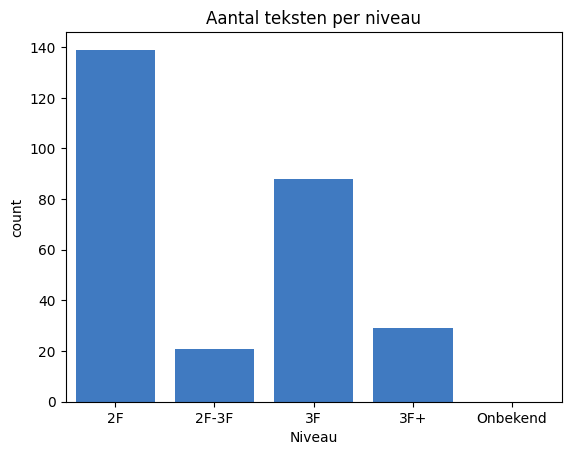

In [6]:
# Aantal teksten per niveau
print(df["Niveau"].value_counts())

sns.countplot(data=df, x="Niveau", order=niveau_volgorde + ["Onbekend"], color="#2a78d6")
plt.title("Aantal teksten per niveau")
plt.show()

genre
Fictie               132
Informatief           39
Fictie / Thriller     33
Fictie / Roman        26
Poëzie                21
Thriller               4
Roman                  2
Name: count, dtype: Int64


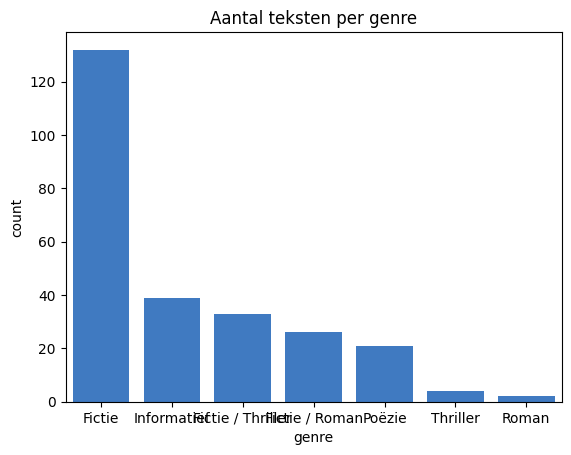

In [7]:
# Aantal teksten per genre
print(df["genre"].value_counts())

sns.countplot(data=df, x="genre", order=df["genre"].value_counts().index, color="#2a78d6")
plt.title("Aantal teksten per genre")
plt.show()

Onderwerp bekend: 100
Onderwerp onbekend: 0
onderwerp
liefde        11
oorlog         7
familie        5
thriller       5
identiteit     4
doorzetten     4
ontmoeting     3
geheimen       3
reizen         3
veerkracht     3
Name: count, dtype: Int64


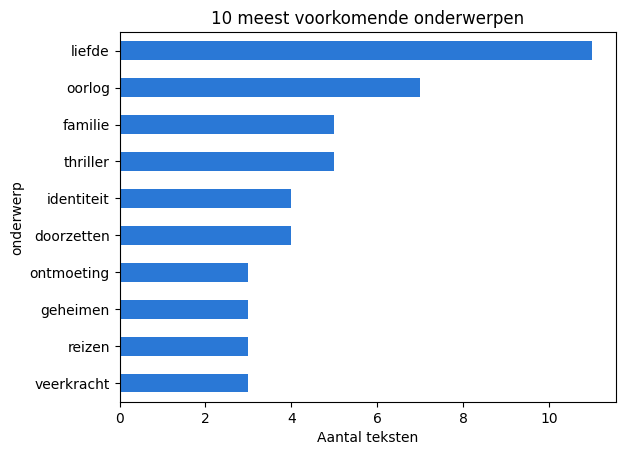

onderwerp onbekend  False
genre                    
Fictie                 73
Fictie / Roman          5
Fictie / Thriller      13
Thriller                2


In [8]:
# Hoeveel teksten hebben een bekend onderwerp?
print("Onderwerp bekend:", (df["onderwerp"] != "Onbekend").sum())
print("Onderwerp onbekend:", (df["onderwerp"] == "Onbekend").sum())

# De 10 meest voorkomende onderwerpen
top10 = df[df["onderwerp"] != "Onbekend"]["onderwerp"].value_counts().head(10)
print(top10)

top10.plot(kind="barh", color="#2a78d6")
plt.title("10 meest voorkomende onderwerpen")
plt.xlabel("Aantal teksten")
plt.gca().invert_yaxis()
plt.show()

# Bij welk genre is het onderwerp bekend?
print(pd.crosstab(df["genre"], df["onderwerp"] == "Onbekend",
                  rownames=["genre"], colnames=["onderwerp onbekend"]))

count    277.0
mean     383.5
std      258.2
min        5.0
25%      184.0
50%      368.0
75%      586.0
max      946.0
Name: geschatte_leestijd_min, dtype: Float64


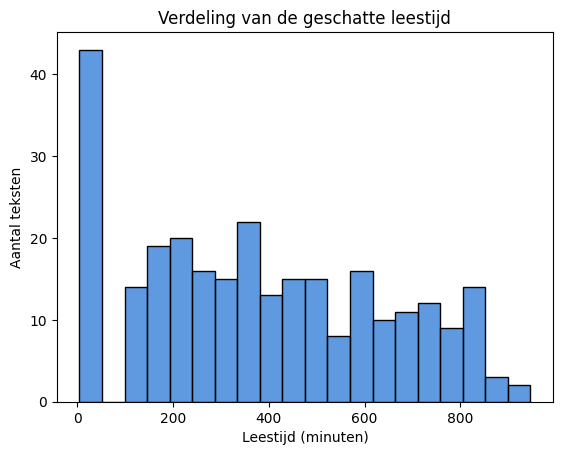

In [9]:
# Kerncijfers van de leestijd
print(df["geschatte_leestijd_min"].describe().round(1))

sns.histplot(data=df, x="geschatte_leestijd_min", bins=20, color="#2a78d6")
plt.title("Verdeling van de geschatte leestijd")
plt.xlabel("Leestijd (minuten)")
plt.ylabel("Aantal teksten")
plt.show()

count    277.0
mean      45.7
std       11.9
min       14.9
25%       36.7
50%       45.4
75%       52.0
max       80.2
Name: leescomplexiteit_score, dtype: Float64


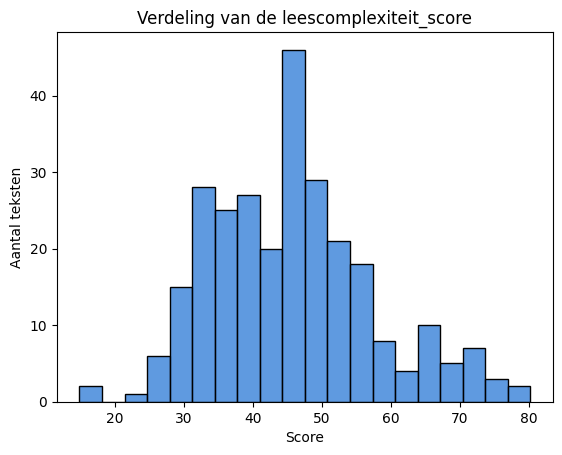

In [10]:
# Kerncijfers van de score
print(df["leescomplexiteit_score"].describe().round(1))

sns.histplot(data=df, x="leescomplexiteit_score", bins=20, color="#2a78d6")
plt.title("Verdeling van de leescomplexiteit_score")
plt.xlabel("Score")
plt.ylabel("Aantal teksten")
plt.show()